In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Постановка проблемы

Предположим, к нам попали данные исследований нескольких (пусть n=3) вакцин;  
В каждом исследовании собирались данные о респондентах, с которых через 1 / 10 / 100 часов собирали оценку самочувствия  

In [2]:
respondents = 1000

def make_research():
  research = {
      "gender": np.random.randint(0,2,respondents),            # 0 - m, 1 - f
      "age": np.random.normal(25.0,20.0,respondents),
      "height": np.random.normal(170.0,15.5,respondents),
      "weight": np.random.normal(65.0,25.0,respondents)
      }

  feeled_bad = 0                                                # считаем, сколько всего людей ощутили себя плохо

  part = np.random.randint(7,20,1)                              # доля респондентов, которые будут подвержены плохому самочувствию
  feeled_bad += part

  research["condition_after_1"] = np.random.normal(
      (5 *                                                      # мат. ожидание сдвигается: если бы исследования и не было, в среднем все ставили бы ровно 5,
       (respondents * (1 - part/100)) +                         # но теперь 5 в среднем поставят меньшее число людей
       1 * (respondents * part/100))                            # остальные захотят поставить 1
      / respondents,

      2.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 7 else -1       # будем считать, что люди более склонны иметь ухудшившееся самочувствие через какое-то время
  part = np.random.randint(
      7 - (got_better * 2),
      20 - (got_better * 5),
      1)
  feeled_bad += part

  research["condition_after_10"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      1.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 3 else -1       # будем считать, что люди более склонны иметь улучшившееся самочувствие через продолжительное время
  part = np.random.randint(
      7 - (got_better * 3),
      20 - (got_better * 7),
      1)
  feeled_bad += part

  research["condition_after_100"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      2.5,
      respondents
      )

  return research

In [3]:
researh_0 = make_research()

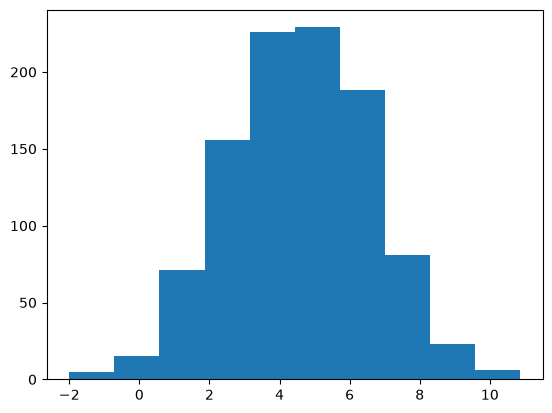

In [4]:
_ =plt.hist(researh_0["condition_after_1"])

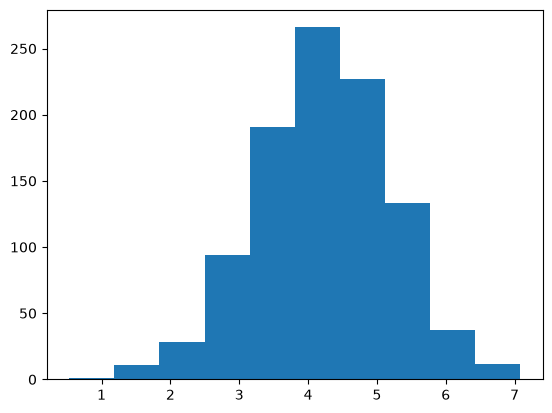

In [5]:
_ =plt.hist(researh_0["condition_after_10"])

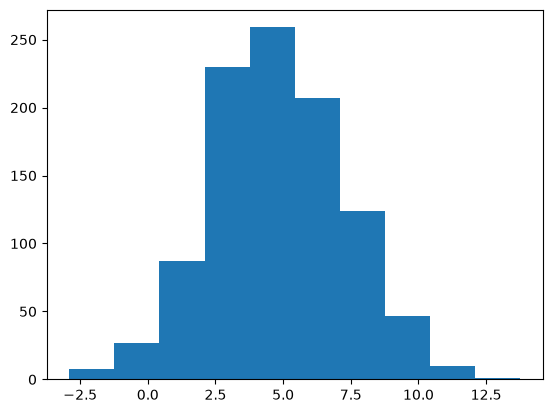

In [6]:
_ =plt.hist(researh_0["condition_after_100"])

# Задание

Мы хотим:
- проверить, что с данными все в порядке (т.к. данные генерили с помощью распределений, у нас могут быть отрицательные числа, которые надо исправить на 0, а также числа больше 10, которые надо исправить на 10) - построить гистограммы и почистить данные
- сравнить между собой результаты исследований разных вакцин и каким-либо образом представить сравнение исследований (т.е., к примеру, показать в одном пространстве сразу 3 исследования, пользуясь признаками "средняя оценка самочувствия после 1 часа", "средняя оценка самочувствия после 10 часов", "средняя оценка самочувствия после 100 часов"
- важно! обратите внимание на цвета, что вы используете

## Очистка данных

Оценки самочувствия ограничиваем диапазоном от 0 до 10.

In [7]:
hours = (1, 10, 100)
columns = [f"condition_after_{hour}" for hour in hours]
colors = ("#0072B2", "#D55E00", "#009E73")
researches = [researh_0, make_research(), make_research()]

raw_scores = np.array([[research[column] for column in columns] for research in researches])
scores = np.clip(raw_scores, 0, 10)
for research, values in zip(researches, scores):
    research.update(zip(columns, values))

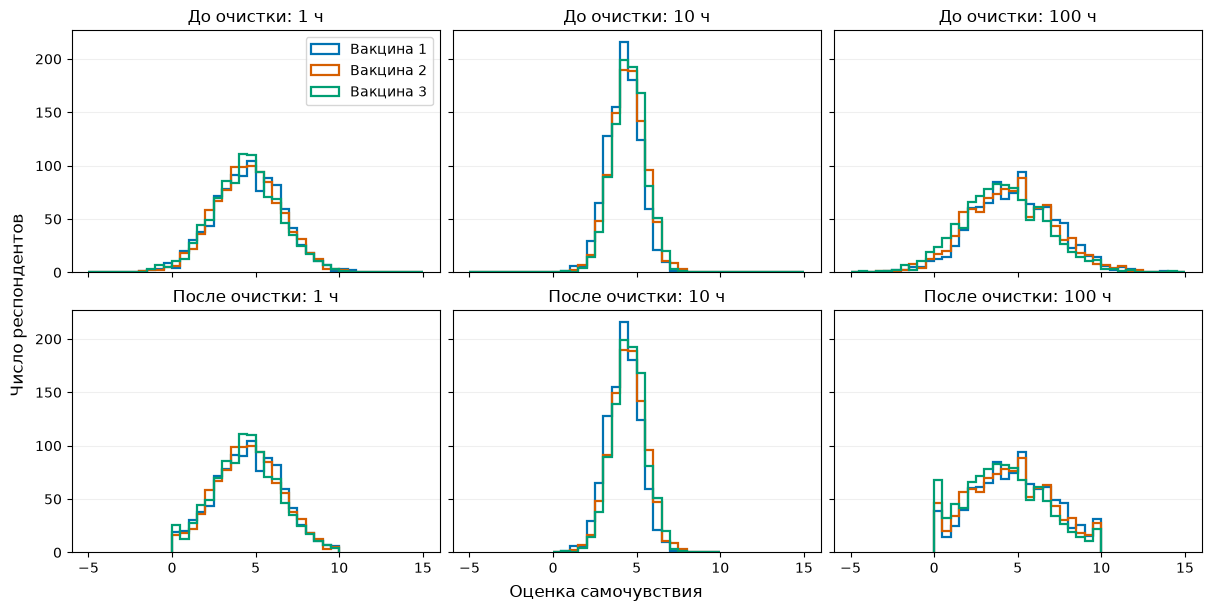

In [8]:
bins = np.arange(np.floor(raw_scores.min()), np.ceil(raw_scores.max()) + 0.5, 0.5)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True, layout="constrained")

for row, (data, title) in enumerate(((raw_scores, "До очистки"), (scores, "После очистки"))):
    for column, hour in enumerate(hours):
        ax = axes[row, column]
        edges = bins if row == 0 else np.arange(0, 10.5, 0.5)
        for index, color in enumerate(colors):
            ax.hist(
                data[index, column], bins=edges, histtype="step", linewidth=1.6,
                color=color, label=f"Вакцина {index + 1}",
            )
        ax.set_title(f"{title}: {hour} ч")
        ax.grid(axis="y", alpha=0.2)

axes[0, 0].legend()
fig.supxlabel("Оценка самочувствия")
fig.supylabel("Число респондентов")
plt.show()

## Сравнение вакцин

Координаты каждой точки — средние оценки через 1, 10 и 100 часов после очистки. Цвета вакцин совпадают с цветами на гистограммах; точки дополнительно различаются формой.

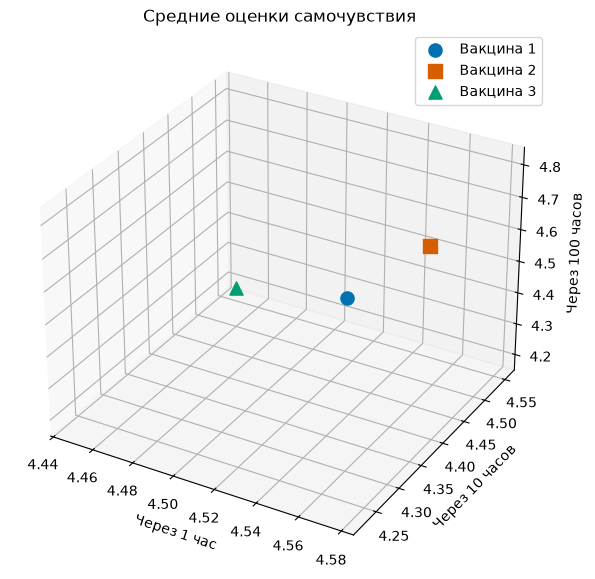

In [9]:
means = scores.mean(axis=2)
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")

for index, (mean, color, marker) in enumerate(zip(means, colors, ("o", "s", "^"))):
    ax.scatter(*mean, color=color, marker=marker, s=90, label=f"Вакцина {index + 1}")

ax.set(
    title="Средние оценки самочувствия",
    xlabel="Через 1 час",
    ylabel="Через 10 часов",
    zlabel="Через 100 часов",
)
ax.legend()
plt.show()